# 04 – Hibaelemzés

A végső modell (DistilBERT 512/3) és a baseline teszthalmazon adott előrejelzései alapján.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from common import FIG_DIR, LABELS_3, LABELS_5, RESULTS_DIR, load_split

BEST = "distilbert_512_3ep"
BASE = "tfidf_logreg"
PRED_DIR = RESULTS_DIR / "predictions"
pd.set_option("display.max_colwidth", 300)


def load_pred(model: str, task: str) -> pd.DataFrame:
    labels = LABELS_5 if task == "5class" else LABELS_3
    df = pd.read_csv(PRED_DIR / f"{model}_{task}.csv")
    df["y_true"] = df["true"].map(labels.index)
    df["y_pred"] = df["pred"].map(labels.index)
    return df


p5 = {m: load_pred(m, "5class") for m in (BASE, BEST)}
p3 = {m: load_pred(m, "3class") for m in (BASE, BEST)}
test_df = load_split()["test"]
assert (p5[BEST]["text"] == test_df["text"]).all() and (p5[BASE]["text"] == test_df["text"]).all()
print(f"teszthalmaz: {len(test_df)} értékelés")

teszthalmaz: 4000 értékelés


## 1. A hibák mérete (5 osztály)

In [2]:
rows = {}
for m, df in p5.items():
    dist = (df["y_true"] - df["y_pred"]).abs()
    rows[m] = {
        "pontos találat": (dist == 0).mean(),
        "1 csillag eltérés": (dist == 1).mean(),
        "2 csillag eltérés": (dist == 2).mean(),
        "3–4 csillag eltérés": (dist >= 3).mean(),
        "a hibák közül szomszédos": (dist == 1).sum() / (dist > 0).sum(),
        "MAE (csillag)": dist.mean(),
    }
error_size = pd.DataFrame(rows)
error_size.to_csv(RESULTS_DIR / "error_size_5class.csv", encoding="utf-8")
error_size.style.format("{:.3f}")

,tfidf_logreg,distilbert_512_3ep
pontos találat,0.561,0.614
1 csillag eltérés,0.360,0.349
2 csillag eltérés,0.057,0.029
3–4 csillag eltérés,0.022,0.008
a hibák közül szomszédos,0.821,0.904
MAE (csillag),0.549,0.435


## 2. Magabiztosság és pontosság

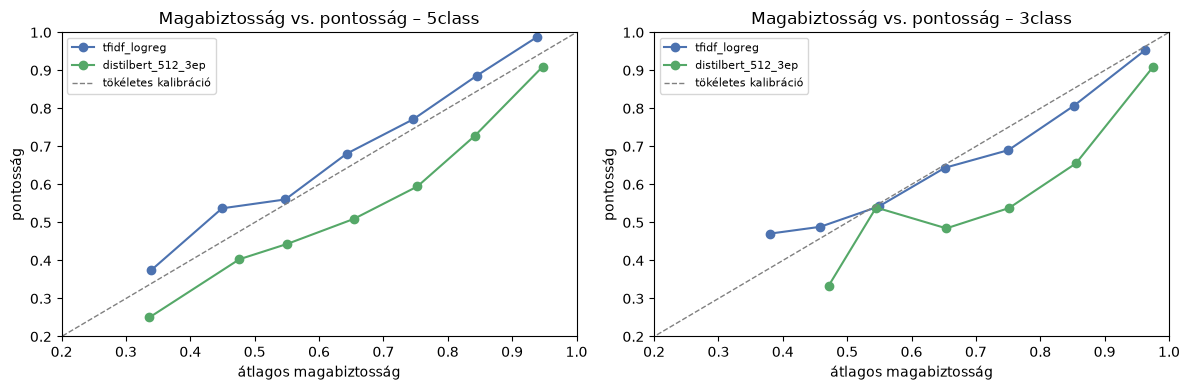

5class: a distilbert_512_3ep előrejelzéseinek 34%-a ≥0.8 magabiztosságú, ezeken a pontosság 81.1% (többin: 51.4%)
3class: a distilbert_512_3ep előrejelzéseinek 81%-a ≥0.8 magabiztosságú, ezeken a pontosság 87.0% (többin: 51.3%)


In [3]:
bins = [0, .4, .5, .6, .7, .8, .9, 1.0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
calib_rows = []
for ax, (task, preds) in zip(axes, (("5class", p5), ("3class", p3))):
    for m, color in ((BASE, "#4C72B0"), (BEST, "#55A868")):
        df = preds[m].copy()
        df["bin"] = pd.cut(df["confidence"], bins=bins, include_lowest=True)
        g = df.groupby("bin", observed=True).agg(n=("correct", "size"), accuracy=("correct", "mean"),
                                                 mean_conf=("confidence", "mean"))
        g = g[g["n"] >= 20]
        ax.plot(g["mean_conf"], g["accuracy"], "o-", color=color, label=m)
        calib_rows += [{"task": task, "model": m, "bin": str(b), **r} for b, r in g.to_dict("index").items()]
    ax.plot([0, 1], [0, 1], ls="--", color="grey", lw=1, label="tökéletes kalibráció")
    ax.set(title=f"Magabiztosság vs. pontosság – {task}", xlabel="átlagos magabiztosság",
           ylabel="pontosság", xlim=(0.2, 1), ylim=(0.2, 1))
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "calibration.png", dpi=200, bbox_inches="tight")
plt.show()

pd.DataFrame(calib_rows).to_csv(RESULTS_DIR / "calibration.csv", index=False, encoding="utf-8")
for task, preds in (("5class", p5), ("3class", p3)):
    df = preds[BEST]
    hi = df["confidence"] >= 0.8
    print(f"{task}: a {BEST} előrejelzéseinek {hi.mean():.0%}-a ≥0.8 magabiztosságú, "
          f"ezeken a pontosság {df.loc[hi, 'correct'].mean():.1%} (többin: {df.loc[~hi, 'correct'].mean():.1%})")

## 3. A két modell összevetése

### 3.1 Egyetértés

In [4]:
agree_rows = {}
for task, preds in (("5class", p5), ("3class", p3)):
    b, d = preds[BASE]["correct"], preds[BEST]["correct"]
    agree_rows[task] = {"mindkettő helyes": (b & d).mean(), "csak DistilBERT helyes": (~b & d).mean(),
                        "csak TF-IDF helyes": (b & ~d).mean(), "mindkettő hibás": (~b & ~d).mean()}
agreement = pd.DataFrame(agree_rows)
agreement.to_csv(RESULTS_DIR / "agreement.csv", encoding="utf-8")
agreement.style.format("{:.1%}")

,5class,3class
mindkettő helyes,44.7%,70.2%
csak DistilBERT helyes,16.6%,10.1%
csak TF-IDF helyes,11.4%,7.0%
mindkettő hibás,27.3%,12.7%


### 3.2 Tagadás és ellentét

In [5]:
PATTERNS = {
    "tagadás (not, n't, never, no …)": r"\b(not|no|never|nothing|nobody|neither|nor|hardly)\b|n't\b",
    "ellentét (but, however, although …)": r"\b(but|however|although|though|yet|except)\b",
}
text_lc = test_df["text"].str.lower()
ling_rows = []
for task, preds in (("5class", p5), ("3class", p3)):
    for name, pat in PATTERNS.items():
        has = text_lc.str.count(pat) >= 2
        for group, mask in ((f"van ({has.sum()})", has), (f"nincs ({(~has).sum()})", ~has)):
            ling_rows.append({"task": task, "jelenség (≥2 előfordulás)": name, "csoport": group,
                              BASE: preds[BASE].loc[mask, "correct"].mean(),
                              BEST: preds[BEST].loc[mask, "correct"].mean()})
ling = pd.DataFrame(ling_rows).set_index(["task", "jelenség (≥2 előfordulás)", "csoport"])
ling["Δ (%-pont)"] = (ling[BEST] - ling[BASE]) * 100
ling.to_csv(RESULTS_DIR / "accuracy_by_phenomenon.csv", encoding="utf-8")
ling.style.format({BASE: "{:.1%}", BEST: "{:.1%}", "Δ (%-pont)": "{:+.1f}"})

### 3.3 Csak a DistilBERT talált

In [6]:
def show(df: pd.DataFrame, n: int = 8, chars: int = 450) -> pd.DataFrame:
    out = df.head(n).copy()
    out["text"] = out["text"].str.slice(0, chars) + np.where(out["text"].str.len() > chars, " …", "")
    return out


b, d = p5[BASE], p5[BEST]
mask = d["correct"] & ((b["y_true"] - b["y_pred"]).abs() >= 2)
only_bert = pd.DataFrame({"text": d["text"], "valódi": d["true"], "TF-IDF": b["pred"], "DistilBERT": d["pred"],
                          "DistilBERT magabizt.": d["confidence"].round(2)})[mask]
print(f"{mask.sum()} ilyen értékelés")
only_bert = only_bert.sample(frac=1, random_state=0)
only_bert.to_csv(RESULTS_DIR / "examples_only_distilbert_right.csv", encoding="utf-8")
show(only_bert)

94 ilyen értékelés


,text,valódi,TF-IDF,DistilBERT,DistilBERT magabizt.
75,If you want PHO in Pittsburgh (Considering the Vietnamese Restaurant selections) I would choose this Place over Tram's Kitchen. The Pho here is more fragrant.,3★,1★,3★,0.70
1252,"Clean and sound haircut This is definitely an old school style barbershop that hasn't seen any modernization except maybe the tools of the barber, but really, everything is vintage. That is what makes a barber shop to what it should be. Too many shops focus on the appearance of their spots and a...",5★,2★,5★,0.46
2486,"Normally, I write big, long reviews, even on ""meh"" places. The Monte Carlo was so thoroughly ""meh"" that I'm just going to give the Cliffs Notes version. Huge lines to check in. Took over half an hour. Only half the desks were staffed. The desk staff were very nice and very professional, though. ...",2★,4★,2★,0.79
509,"why do these guys suck? how hard is it to ring a bell to see if the receiver is home? I've had multiple issues with them, and wish Amazon would stop using them.",1★,5★,1★,0.95
466,"I went into this store today ONLY to get the $2.99 milk special they had. So I naturally assumed that I would be in and out in 10 min or less. However, I get in, get my milk and I'm in line for more than 10 min. There were 5 people in line and only 1 register open around 3pm. I efinitely would h...",3★,1★,3★,0.73
2681,Stunned....Stack blows this place out of the water. Me and the lady had the filet and the Kobe skirt. Both were very undesirable and borderline required a complaint to a manager. I really can't believe the dryness of the filet. Literally unbelievable. If you want good filet at the mirage stick t...,1★,4★,1★,0.93
2706,"The owner is wonderful, along with his staff. Have been coming here for almost a year. We have tried other Indian restaurants, but I couldn't eat their food, until we ate here. We love the food here. We drove almost 1/2-hour to get here. The kitchen is like a magic work shop, because all my life...",5★,1★,5★,0.70
3556,"3rd time here for lunch and every time I am blown away. They put a spin on Mexican food that just flat out works. This is not what I would think of as a lunch place, but wow. The food is flat out great! I mean award winning good. The service is outstanding. I only had water last time and I think...",5★,1★,5★,0.78


### 3.4 Csak a baseline talált

In [7]:
mask = b["correct"] & ((d["y_true"] - d["y_pred"]).abs() >= 1)
only_base = pd.DataFrame({"text": d["text"], "valódi": d["true"], "TF-IDF": b["pred"], "DistilBERT": d["pred"],
                          "DistilBERT magabizt.": d["confidence"].round(2)})[mask]
print(f"{mask.sum()} ilyen értékelés")
only_base = only_base.sample(frac=1, random_state=0)
only_base.to_csv(RESULTS_DIR / "examples_only_baseline_right.csv", encoding="utf-8")
show(only_base)

455 ilyen értékelés


,text,valódi,TF-IDF,DistilBERT,DistilBERT magabizt.
3033,Best brisket in Charlotte - no sauce require.... but the Midwood sauce is great. And I love that the baked beans are more like chili than anything else.,5★,5★,4★,0.58
580,"Mmm tasty! Thai Basil and Thai Curries are very solid - near the top of the heap. One of the big stars here is their Brown Rice which is a wild red variety. Soaks up the sauce/curry perfectly. Super nice service, and I can't wait to go back more often. Been twice in two months. They deserve to b...",4★,4★,5★,0.49
2466,"For the price, I expected more. The ambiance was not as impressive as I thought a roof top restaurant would be. The hostess was unattentive and the staff did not treat us as valued guests. Not to say the service was bad, but that there was nothing to write home about. After telling the waitress ...",3★,3★,2★,0.60
3545,"This place made me laugh the first time I ever saw it. How many backstreet takeaway noodle bars have you ever stumbled across with Ipads to use whilst you wait for your food? The food itself was good, although nowhere near as good as the Red Box Noodle Bar just around the corner. In fact, on the...",4★,4★,3★,0.85
973,If you love a live band and 64 beer choices this is your place.,5★,5★,4★,0.37
2813,Not worth the money. The Kobe burger was not season well. It's overrated don't waste your money or time.,1★,1★,2★,0.62
114,Le Lab is so enjoyable! A lounge like vibe! Love everything here! The cocktails here are all well crafted and balanced! The bartenders having so much fun lighting up everything in flames! What a show! Service though a little slow in the beginning but did pick up. We tried: Jerky Jack Lab ($14) -...,4★,4★,5★,0.65
1389,"Don't like tobacco / hookah smoke? Sit outside with a view of the parking lot as you *inhale* their absolutely delicious and satisfying Falafel wrap. At $9 and change, it's all the money for a falafel wrap, but I think their spicy serrano 'tapenade' is so good (similar to Sababa's spicy green sp...",4★,4★,5★,0.57


## 4. Súlyos, magabiztos hibák

In [8]:
dist = (d["y_true"] - d["y_pred"]).abs()
gross = pd.DataFrame({"text": d["text"], "valódi": d["true"], "DistilBERT": d["pred"],
                      "magabizt.": d["confidence"].round(2), "eltérés": dist})
gross = gross[(dist >= 2) & (d["confidence"] >= 0.6)].sort_values(["eltérés", "magabizt."], ascending=False)
print(f"{len(gross)} súlyos, magabiztos hiba ({len(gross) / len(d):.1%} a teszthalmazból)")
gross.to_csv(RESULTS_DIR / "examples_gross_errors.csv", encoding="utf-8")
show(gross, n=12)

80 súlyos, magabiztos hiba (2.0% a teszthalmazból)


,text,valódi,DistilBERT,magabizt.,eltérés
1042,"I am still leaving zero stars for the Fiesta, but Crystal, the manager of housekeeping, was a gem of a lady, really cared and helped us with empathy and understanding, give her a promotion, please...Fiesta and Station Casino, listen to me...you have a gem of a oroperty, mountain views, minutes f...",1★,5★,0.80,4
1753,"...At first glace, the soup at Pho Bang New York was dark and murky that went from transparent clean-cut, all business soup up top, to cloudy, mysterious and all party near the bottom - I present to you, the Soup Mullet...",5★,1★,0.76,4
2518,I can't even begin to describe how good this place is. Trust the reviews and do yourself a favor ...go try it out! While your there...try the pork belly tacos. They are sinfully good. You cannot go wrong with Soul Gastrolounge.,5★,1★,0.74,4
3227,"Oh Kohls, why do you torment me with all the 20% off coupons you incessantly send me and the non stop sales? Good grief, last week you offered $15 in bonus bucks for every $50 spent. So hard to resist...but I must! Can't fit much more into my closet. Perhaps I can just drop another dress size an...",5★,1★,0.60,4
693,"We had an ant issue and called APS after calling two other Pest Control companies. One company never answered their number and the other never showed for the scheduled appointment. APS came, APS sprayed the house and the next day the ants are gone.",4★,1★,0.98,3
1824,"I drove by this location on April 5, 2011 and saw that the restaurant has been closed. All of the signs were off of the building.",4★,1★,0.92,3
229,"Erica D. Is amazing! she turned my wedding dress shopping experience totally around. When i first came in to David's I was told to look around while they got my consultant. I was given a lady name Jenny. Very rude, unprofessional, had an attitude with my mom and also mother in law. She pick dres...",2★,5★,0.91,3
1090,Looks like they closed down! Is it for good? I didn't see any relocating notes....so I am not sure if they are opening elsewhere in town. Hopefully they update their website or facebook soon. Crosses fingers!,4★,1★,0.79,3
3638,"I'm used to getting horrible service and sub-par food from Hawaiian places. It must be because I frequent Aloha Kitchen more than I should -- but what can I do when it's the closest thing to UNLV? Now let's look at Kauai Cafe. The server was awfully kind, the kitchen staff look like they enjoy t...",5★,2★,0.76,3
737,"It was slightly overpriced, but for the atmosphere and ambiance it's worth it. The waitor was friendly and gave us his recommendations on every possible section of the menu. All you hear are exotic birds chirping and tigers roaring every 5 seconds. I would also like a giant mushroom in my room. ...",1★,4★,0.73,3


### 4.1 Semleges osztály

In [9]:
n3 = p3[BEST]
neutral = n3[n3["true"] == "semleges"]
neutral_summary = pd.DataFrame({
    "arány": neutral["pred"].value_counts(normalize=True),
    "átlagos magabiztosság": neutral.groupby("pred")["confidence"].mean(),
}).reindex(LABELS_3)
display(neutral_summary.style.format({"arány": "{:.1%}", "átlagos magabiztosság": "{:.2f}"}))

wrong_neutral = neutral[~neutral["correct"]].sort_values("confidence", ascending=False)
wrong_neutral[["text", "true", "pred", "confidence"]].to_csv(RESULTS_DIR / "examples_neutral_errors.csv",
                                                             encoding="utf-8")
show(wrong_neutral[["text", "pred", "confidence"]], n=6)

,arány,átlagos magabiztosság
pred,,
negatív,24.4%,0.84
semleges,51.1%,0.79
pozitív,24.5%,0.85


,text,pred,confidence
3153,"Do get their Showgirl dog, which showcases all the ingredients you can load up on for a hot dog to scream supreme! This hot dog spot is conveniently located near Walgreens, semi-corner of Planet Hollywood - on the outside. The staff brings the dogs out when ready. Their French fries were fried a...",pozitív,0.993636
1893,"I'm disappointed. The quality of food and service on my second visit diminished greatly. It seems to me that they strived to have delicious and high quality food for the first month, then became complacent and allowed the service and the food to go downhill from there. How unfortunate. I don't e...",negatív,0.993510
2680,"I enjoy this store, it's location and how well maintained it is. They have so many great selections of all sorts of items for every room and person in the family. Shoes, bags, clothes and toys and even items for pets. Great place.",pozitív,0.993247
995,This was my first visit to this restaurant and I may not be back. It took the waiter about 4-5 minutes just to greet our table. We ordered an appetizer and he didn't come back right away to take our actual order. We ordered the quattro al forno which was supposed to have 4 different types of pas...,negatív,0.993126
3005,"This place I feel is over rated. They have huge burgers at a fair price, but their meat has no flavor. I have given this place three chances and have yet to walk away feeling fullfilled and not nauseous. Way too much grease and not enough flavor. Their fries are often soggy. Not impressed.",negatív,0.993048
815,Wow really bad service tonight! The lady was rude and cut me off 3 times. Then i asked a simple question and was ignored until I pushed the button and got another girl on the intercom. Really disappointed.,negatív,0.992918
